# MODULATION
In this lab session, we’ll learn how to simulate signal modulation. The goal is to develop a deep understanding of the basic concepts behind sending, receiving, and working with encoded information. Let's begin by representing a continuous sinusoidal signal using discrete-time samples.

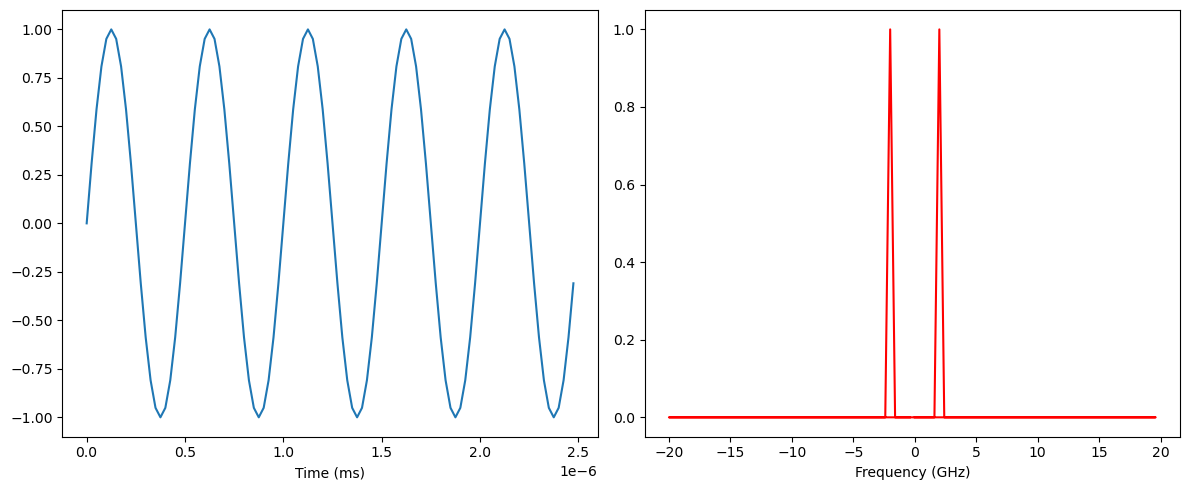

In [3]:
import numpy as np 
import matplotlib.pyplot as plt

#################
# Data
#################

F = 2e9        # Frequency of the signal that we want to simulate, Hz
W = 2 * np.pi * F
cycles = 5       # Number of cycles that we want to represent
T = cycles*(1/F)  # Total time duration of the signal

#################
#################

fs = 20 * F# Sampling rate frequency for our digital representation
ts = 1/fs
time = np.arange(0,T,ts)            #Generates the time vector
Signal = np.sin(W * time)

fft_freq = np.fft.fftfreq(len(time), d=ts)  #Generates the frequency vector
FFT = np.fft.fft(Signal)
FFT_norm = FFT/np.max(abs(FFT))

f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(12, 5))
ax1.plot(time*1e3,Signal)
ax1.set_xlabel('Time (ms)')
ax2.plot(fft_freq*1e-9,abs(FFT_norm),'red')
ax2.set_xlabel('Frequency (GHz)')
plt.show()

# Digital Signal Generation
First, we’ll generate a sequence of bits that will serve as our transmitted data. The key parameters are:

- Number of bits (N)
- Bit time (T): slot of time associated with the transmission of 1 bit
- Signal frequency/Signal Bandwidth/ Speed of transmission (B = 1/T)
- Sampling frequency (fs): Key in all simulation systems, is the number of samples taken per second from a continuous signal to convert it into a discrete. Should be at least twice the maximum frequency of our system. CARE WITH THIS VALUE OR WE WILL DESTROY OUR COMPUTER
- Sampling time (ts = 1/fs)

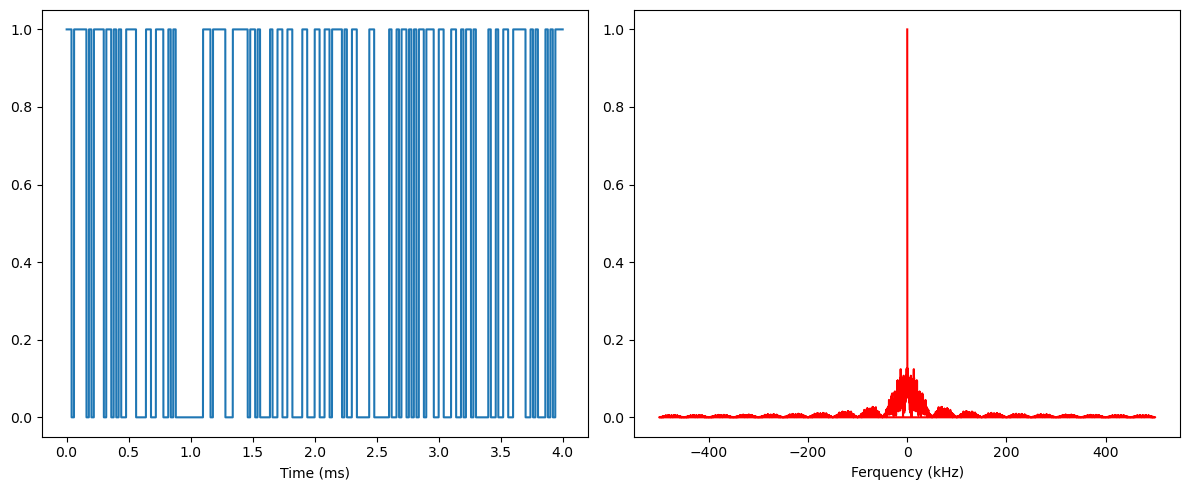

In [19]:
import numpy as np 
import matplotlib.pyplot as plt

#################
# Data
#################

N = 200 # Number of bits
B = 50e3 # Speed of the signal, Hz

#################
#################

T = 1/B
fs = 20*B
ts = 1/fs
Bits = np.random.randint(0, 2, N)                        #Generates the information
Bit_wave = np.repeat(Bits, T/ts)                         #Extendes te information to the appropiated duration
time = np.linspace(0, T*N, len(Bit_wave))                #Generates the time vector
sampling_rate = 1/(time[1] - time[0])                    #Calculate the sampling rate from the time vector
fft_freq = np.fft.fftfreq(len(time), d=1/sampling_rate)  #Generates the frequency vector

FFT = np.fft.fft(Bit_wave)
FFT_norm = FFT/np.max(abs(FFT))

f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(12, 5))
ax1.plot(time*1e3,Bit_wave)
ax1.set_xlabel('Time (ms)')
ax2.plot(fft_freq*1e-3,abs(FFT_norm),'red')
ax2.set_xlabel('Ferquency (kHz)')
plt.show()


# RF signal
Now, we are going to transmit the information using RF, just like a WiFi router. The RF signal will have a higher frequency than the bandwidth of the bit wave, so for the simulation, we will need to redefine the sampling rate to match this higher frequency. We also need to increase the bandwidth of the bit wave; otherwise, the time vector would get way too big. This is really just an issue for simulation.

- Simulate a digital modulated signal over a RF carrier, assume 100 MHz for the baseband signal and 0.5 GHz for the RF carrier.


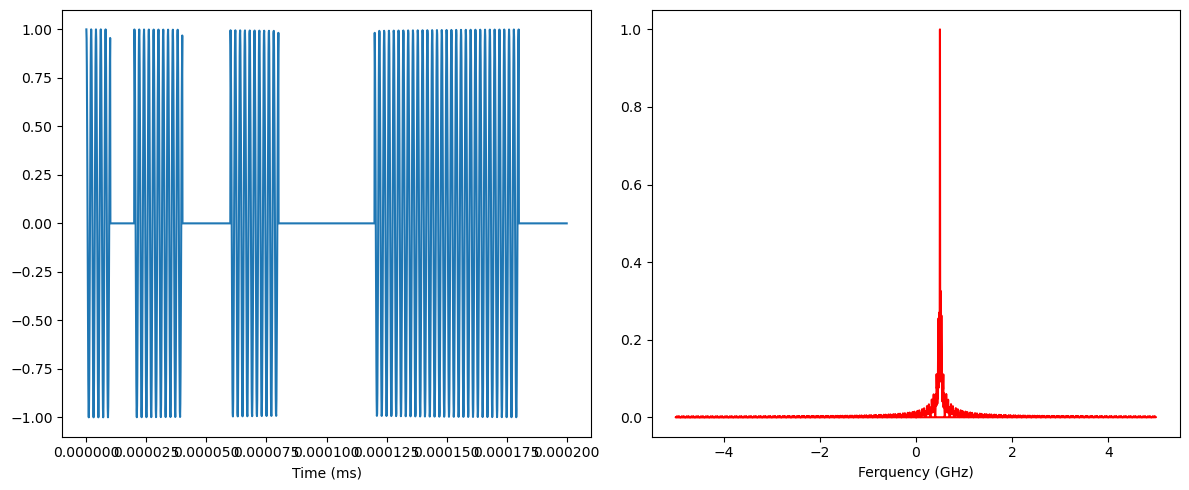

In [61]:
#################
# Data
#################

N = 20          # Number of bits
B = 100e6       # Speed of the signal (100 MHz)
f_rf = .5e9      # Carrier frequency (0.5 GHz)

#################
# Configuración técnica
#################

T = 1/B         # Duración de un bit
fs = 20 * f_rf     # Frecuencia de muestreo (2.5 GHz para ver bien la portadora de 0.5)
ts = 1/fs

#################
# Generación señales
#################

Bits = np.random.randint(0, 2, N)                         # Genera la información
Bit_wave = np.repeat(Bits, T/ts)               # Extiende la info a la duración apropiada

# Corrección del vector de tiempo: debe tener el mismo largo que Bit_wave
time = np.linspace(0, T*N, len(Bit_wave))                #Generates the time vector

#################
# Portadora RF y Modulación
#################

carrier = np.exp(1j * 2 * np.pi * f_rf * time)
modulated_signal = Bit_wave * carrier  # Modulación ASK

#################
# Análisis de Frecuencia (FFT)
#################

sampling_rate = 1/(time[1] - time[0])
fft_freq = np.fft.fftfreq(len(time), d=1/sampling_rate)

FFT = np.fft.fft(modulated_signal)
FFT_norm = np.abs(FFT) / np.max(np.abs(FFT))

#################
# Gráficas
#################

f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(12, 5))
ax1.plot(time*1e3,np.real(modulated_signal))
ax1.set_xlabel('Time (ms)')
ax2.plot(fft_freq*1e-9,abs(FFT_norm),'red')
ax2.set_xlabel('Ferquency (GHz)')
plt.show()

# Microwave Photonic Modulation
The RF signal can be upconverted to the optical domain using an optical amplitude modulator. However, simulating this is highly demanding since it requires a sampling rate of at least twice the optical carrier frequency, which is in the THz range.

In [53]:
#################
# Data
#################

N = 100             # Number of bits
B = 500e6             # Speed of the signal, Hz
f_rf = 10e9            # RF 
f_o = 1.934*(10**14)  # Optical frequency

#################
#################

T = 1/B
fs = 2*f_o
ts = 1/fs
Bits = np.random.randint(0, 2, N)                        #Generates the information
print('Vector length = ' + str((N*T/ts)))

Vector length = 77360000.0


As we can see, this is very impractical, so we have two options: either simulate only the RF upconversion without bandwidth details (no information or digital signal) or work in the frequency domain, assuming ideal linear modulation. First we will start simulating only the upconversion of the RF signals.

Vector length = 760001


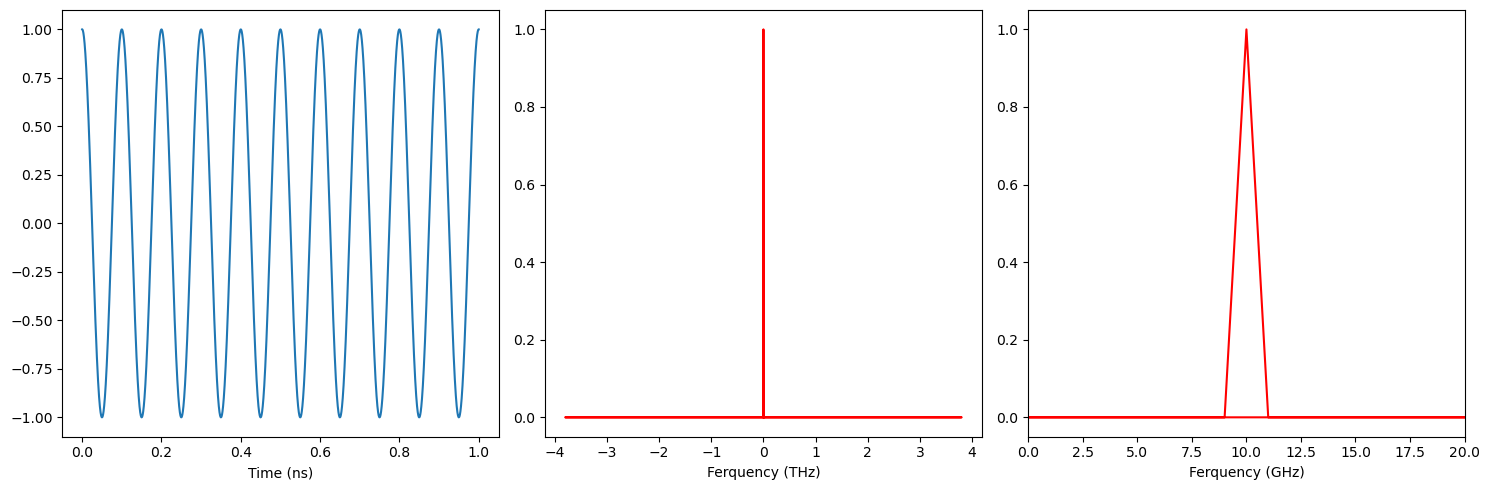

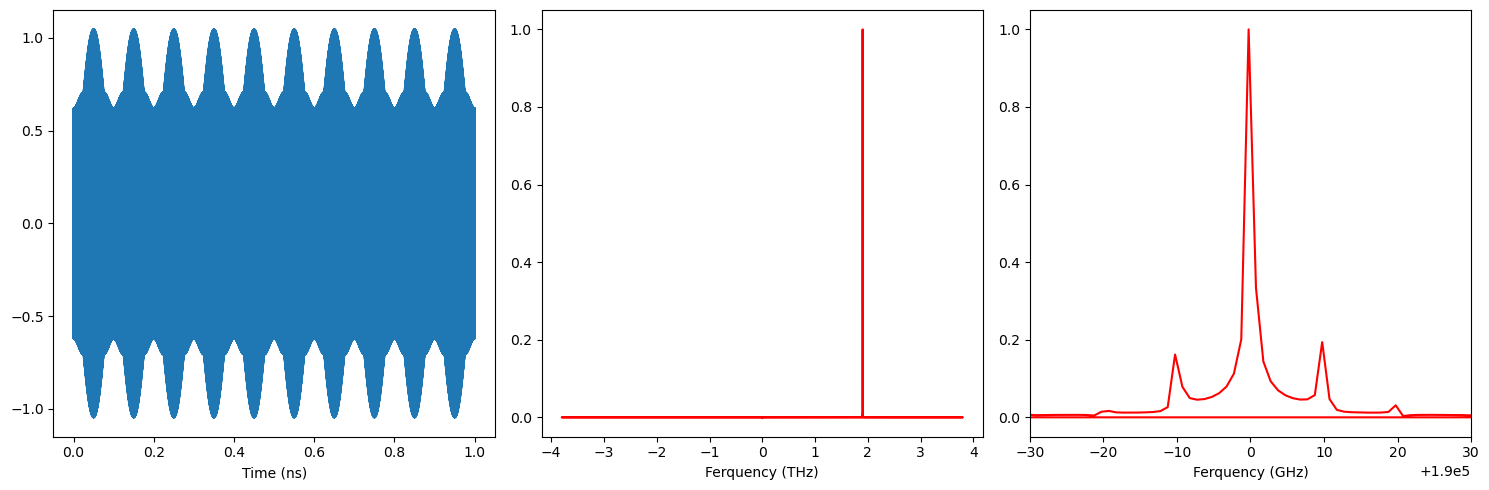

In [62]:
#################
# Data
#################

cycles = 10            # Number of cycles of the RF signal
f_rf = 10e9            # RF 
f_o = 1.9e14           # Optical frequency

#################
#################

fs = 4*f_o
ts = 1/fs
time = np.arange(0, cycles*(1/f_rf), ts)                 #Generates the time vector
sampling_rate = 1/(time[1] - time[0])                    #Calculate the sampling rate from the time vector
fft_freq = np.fft.fftfreq(len(time), d=1/sampling_rate)  #Generates the frequency vector
RF_signal = np.exp(1j*2*np.pi*f_rf*time)
beta = 0.5
Mod = (1/np.sqrt(2))*(np.exp(1j*2*np.pi*f_o*time)*(1 + 1j*np.exp(1j*beta*np.real(RF_signal))))
print('Vector length = ' + str(len(time)))

FFT = np.fft.fft(RF_signal)
FFT_norm = FFT/np.max(abs(FFT))
FFT2 = np.fft.fft(Mod)
FFT_norm2 = FFT2/np.max(abs(FFT2))

#RF signal sampled to optical carrier speed
f, (ax1, ax2, ax3) = plt.subplots(1, 3, tight_layout=True, figsize=(15, 5))
ax1.plot(time*1e9,np.real(RF_signal))
ax1.set_xlabel('Time (ns)')
ax2.plot(fft_freq*1e-14,abs(FFT_norm),'red')
ax2.set_xlabel('Ferquency (THz)')
ax3.plot(fft_freq*1e-9,abs(FFT_norm),'red')
ax3.set_xlabel('Ferquency (GHz)')
ax3.set_xlim(0,20)
plt.show()

#Optical signal 
f, (ax1, ax2, ax3) = plt.subplots(1, 3, tight_layout=True, figsize=(15, 5))
ax1.plot(time*1e9,np.real(Mod))
ax1.set_xlabel('Time (ns)')
ax2.plot(fft_freq*1e-14,abs(FFT_norm2),'red')
ax2.set_xlabel('Ferquency (THz)')
ax3.plot(fft_freq*1e-9,abs(FFT_norm2),'red')
ax3.set_xlabel('Ferquency (GHz)')
ax3.set_xlim((f_o-3*f_rf)*1e-9,(f_o+3*f_rf)*1e-9)
plt.show()

This first option is useful when analyzing the spectral performance of optical devices, such as filters, where simulating the actual signal information isn’t necessary—only the RF carrier matters. However, for applications like simulating optical dispersion in a fiber and its effect on transmitted data, we need to generate a bit sequence. As we’ve seen, though, it’s impossible to sample information at the speed of the optical carrier. So what is the solution??

![My Image](Pic1.png)

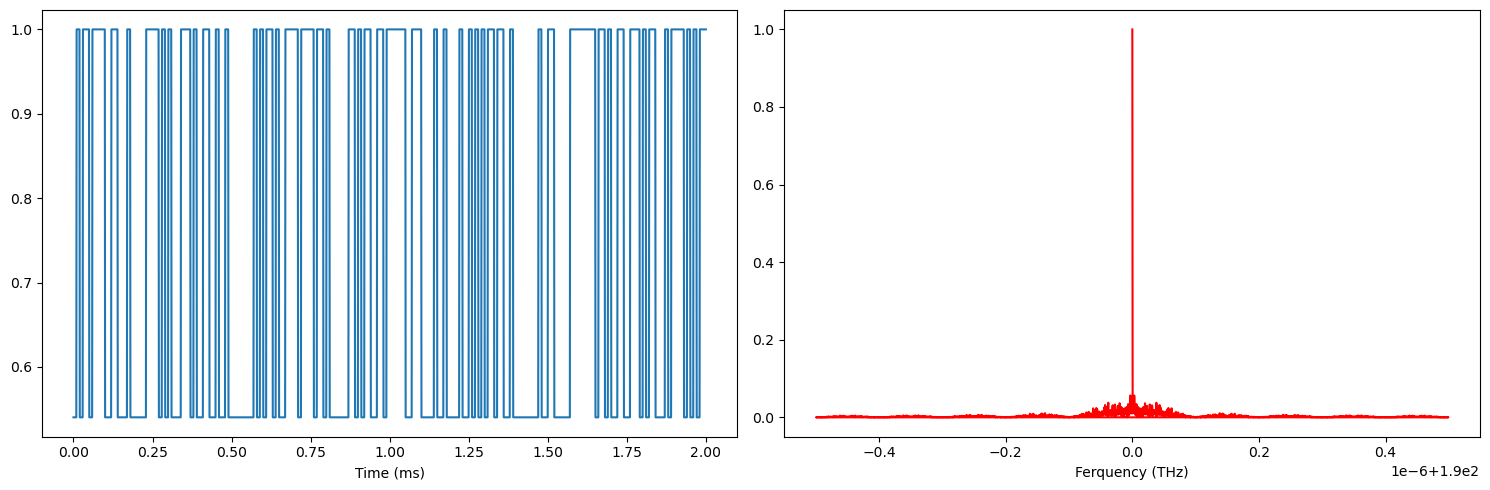

In [63]:
#################
# Data
#################

N = 200 # Number of bits
B = 100e3 # Speed of the signal, Hz
f_o = 1.9e14

#################
#################

T = 1/B
fs = 10*B
ts = 1/fs
Bits = np.random.randint(0, 2, N)                        #Generates the information
Bit_wave = np.repeat(Bits, T/ts)                         #Extendes te information to the appropiated duration
time = np.linspace(0, T*N, len(Bit_wave))                #Generates the time vector
beta = 1
Mod = (1j + np.exp(1j*beta*Bit_wave))
sampling_rate = 1/(time[1] - time[0])                    #Calculate the sampling rate from the time vector
fft_freq = np.fft.fftfreq(len(time), d=1/sampling_rate)  #Generates the frequency vector

FFT = np.fft.fft(Mod)
FFT_norm = FFT/np.max(abs(FFT))

f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(15, 5))
ax1.plot(time*1e3,np.real(Mod))
ax1.set_xlabel('Time (ms)')
ax2.plot((fft_freq+f_o)*1e-12,abs(FFT_norm),'red')
ax2.set_xlabel('Ferquency (THz)')
plt.show()

---------------------------------------      EXCERCISE       ---------------------------------------
---------------------------------------------------------------------------------------------------------------------

Now, let's explore what happens when we introduce a 100 MHz bandwidth modulated signal (similar to an Internet signal in an optical fiber) into a resonant structure, which could represent a fiber link with defects or reflections. For doing so use what you have learn before, try to find the most optimal way for simulating this signal in the optical domain. 

Ring details:
- Round trip = 5 ns
- Loss factor = 0.95

![My Image](Pic2.png)

Represent in a figure:
- The original signal vs time
- The optical spectrum of the filter/cavity and the spectrum of the signal after modulation
- The final response after going into the cavity vs time.

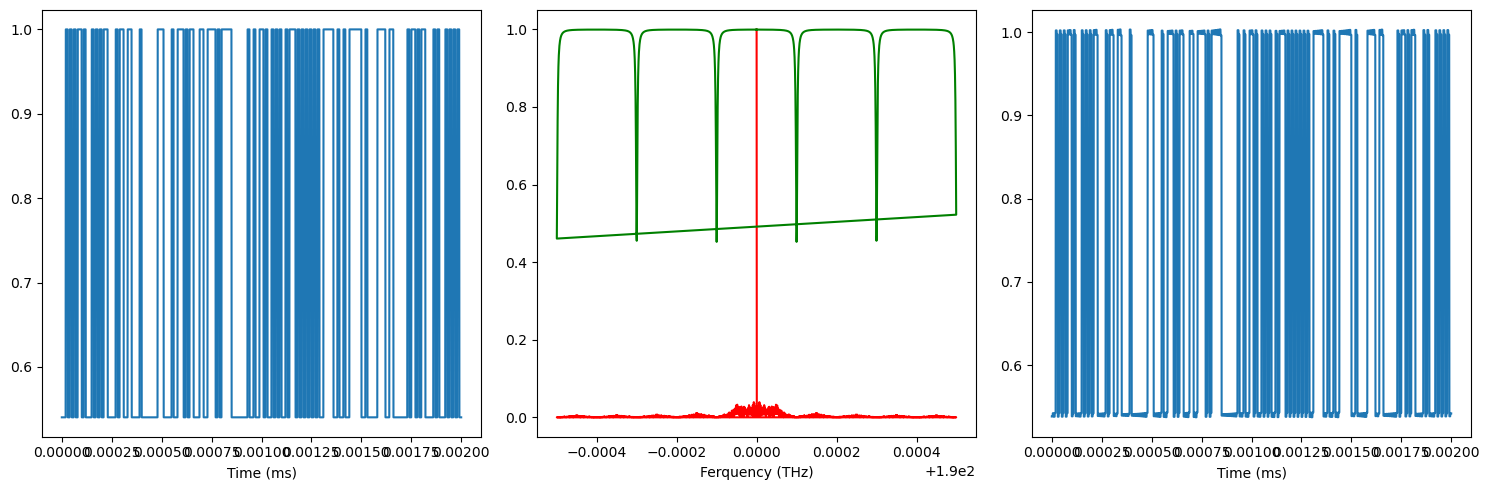

In [79]:
def Ring(coupling, round_trip, losses, frequency, phase_shift):
    H_r = (coupling - losses*np.exp(1j*2*np.pi*frequency*round_trip + 1j*phase_shift))/(1 - coupling*losses*np.exp(1j*2*np.pi*frequency*round_trip + 1j*phase_shift))
    return H_r

#################
# Data
#################

N = 200                 # Number of bits
B = 100e6               # Speed of the signal, Hz
c = 3e8                 # Speed of light 
f_o = 1.9e14            # Optical frequency
wl_o = c/f_o            # Central wavelength
r = 0.99                # transmission
a = 0.95                # loss factor per round trip
ring_round_trip = 5e-9  # seconds
PS = np.pi              # Phase Shift of the ring (rad)

#################
#################

T = 1/B
fs = 10*B
ts = 1/fs
Bits = np.random.randint(0, 2, N)                        #Generates the information
Bit_wave = np.repeat(Bits, T/ts)                         #Extendes te information to the appropiated duration
time = np.linspace(0, T*N, len(Bit_wave))                #Generates the time vector
beta = 1
Mod = (1j + np.exp(1j*beta*Bit_wave))
sampling_rate = 1/(time[1] - time[0])                    #Calculate the sampling rate from the time vector
fft_freq = np.fft.fftfreq(len(time), d=1/sampling_rate)  #Generates the frequency vector

ring_response = Ring(r, ring_round_trip, a, fft_freq, PS)

FFT = np.fft.fft(Mod)
FFT_norm = FFT/np.max(abs(FFT))

IFFT = np.fft.ifft(ring_response * FFT)

f, (ax1, ax2, ax3) = plt.subplots(1, 3, tight_layout=True, figsize=(15, 5))
ax1.plot(time*1e3,np.real(Mod))
ax1.set_xlabel('Time (ms)')
ax2.plot((fft_freq+f_o)*1e-12,abs(FFT_norm),'red')
ax2.plot((fft_freq+f_o)*1e-12,abs(ring_response)**2,'green')
ax2.set_xlabel('Ferquency (THz)')
ax3.plot(time*1e3,np.real(IFFT))
ax3.set_xlabel('Time (ms)')
plt.show()